# Experiment comparison
Compare saved experiment metrics without training or inference. Other compatible classification checkpoints can also be included.

Run the cells in order. Start with the inventory, then select runs in `RUNS`. Tables use validation for model selection; test results are descriptive final evaluations. Missing metadata stays missing: folder names are labels, not configuration evidence.

Requirements: PyTorch, pandas, NumPy, Matplotlib, IPython. Load only trusted local checkpoints. Checkpoints are read one at a time on CPU; model and optimizer tensors are discarded after extracting metrics.

In [10]:
from pathlib import Path
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
MODELS_DIR = PROJECT_ROOT / "output" / "models"
pd.set_option("display.max_columns", 30)

## 1. Available checkpoints
The inventory reads filenames and sizes only. Prefer `last.pth`: it usually contains the full history and may include the final test evaluation of the best model. `best.pth` can contain a shorter history and no test metrics.

In [11]:
inventory = pd.DataFrame([
    {"checkpoint": str(p.relative_to(MODELS_DIR)), "size_mb": round(p.stat().st_size / 2**20, 1)}
    for p in sorted(MODELS_DIR.rglob("*.pth"))
])
display(inventory)

,checkpoint,size_mb
0,backups\backup_v0_20epochs_2026-10-16.pth,90.1
1,backups\backup_v2_S1_20epochs_2026-10-14.pth,90.0
2,backups\backup_v2_S2_20epochs_2026-10-14.pth,90.0
3,backups\backup_v2_S3_20epochs_2026-10-08.pth,90.1
4,backups\backup_v3_20epochs_2026-10-12.pth,90.0
5,v0_15epochs_2026-10-16.pth,90.1
6,v0_20epochs_2026-10-16.pth,90.1
7,v0_20epochs_2026-10-16_2.pth,90.1
8,v2_S1_20epochs_2026-10-14.pth,90.0
9,v2_S2_15epochs_2026-10-14.pth,90.0


## 2. Select experiments
Paths below are relative to `MODELS_DIR` (absolute paths also work). Keep `RUNS` empty to select one `last.pth` per run automatically, excluding backup folders. Use explicit entries to compare a smaller group.

`METADATA` supplies optional, manually verified descriptions for older checkpoints. Never infer Kmin, color space, architecture or freezing policy from a folder name. Manual metadata is displayed separately and does not override saved metrics.

In [14]:
RUNS = {
    # "v4 baseline": "valid_v4_cumulative_rank_adaptive_MSB_20261022/last.pth",
    # "v4 scheduler": "valid_v4_Kmin128_LRO_20261103/last.pth",
}
METADATA = {
    # "v4 baseline": {"architecture": "ResNet50", "Kmin": None, "color_space": "RGB"},
}

if not RUNS:
    RUNS = {
        str(p.parent.relative_to(MODELS_DIR)): p
        for p in sorted(MODELS_DIR.rglob("last.pth"))
        if not any("backup" in part.lower() for part in p.relative_to(MODELS_DIR).parts)
    }
print(f"Selected {len(RUNS)} checkpoints.")

Selected 12 checkpoints.


In [15]:
# run this cell to see all the models selected for evaluation. You can also modify the RUNS dictionary above to select specific checkpoints.
RUNS

{'valid_v0_20261023': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v0_20261023/last.pth'),
 'valid_v0_YCbCr_20261023': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v0_YCbCr_20261023/last.pth'),
 'valid_v0_YCoCgR_20261026': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v0_YCoCgR_20261026/last.pth'),
 'valid_v3_cumulative_rank_adaptive_20261020': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v3_cumulative_rank_adaptive_20261020/last.pth'),
 'valid_v3_cumulative_rank_adaptive_20261021': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v3_cumulative_rank_adaptive_20261021/last.pth'),
 'valid_v3_cumulative_rank_adaptive_YCbCr_20261022': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v3_cumulative_rank_adaptive_YCbCr_20261022/last.pth'),
 'valid_v4_cumulative_rank_adaptive_MSB_20261022': WindowsPath('C:/Users/Edward/Desktop/AARHUS/output/models/valid_v4_cumulative_rank_adaptive_MSB_20261

## 3. Read saved results and check comparability
`val_accuracy` is measured at the minimum-validation-loss epoch, not the independently highest-accuracy epoch. Test metrics carry their own epoch. A saved split fingerprint checks the partition and label mapping, not the contents of the original image files. Verify that test datasets also contain the same examples; older checkpoints may not record their identity.

Accuracy uses percent (0–100). Per-class metrics below are converted to percent too. Training time excludes validation, saving and setup; different hardware or timing coverage makes time comparisons approximate.

In [16]:
def fingerprint(value):
    if value is None:
        return None
    return hashlib.sha256(json.dumps(value, sort_keys=True, separators=(",", ":")).encode()).hexdigest()


def extract_run(label, path):
    checkpoint = torch.load(path, map_location="cpu", weights_only=True)
    history = pd.DataFrame(checkpoint.get("history", []))
    best_epoch = checkpoint.get("best_epoch")
    best_rows = history.loc[history["epoch"].eq(best_epoch)] if "epoch" in history else pd.DataFrame()
    best = best_rows.iloc[-1].to_dict() if not best_rows.empty else {}
    test = checkpoint.get("test_metrics") or {}
    config = checkpoint.get("config_net") or checkpoint.get("CONFIG_NET") or {}
    optimizer_groups = checkpoint.get("optimizer_state_dict", {}).get("param_groups", [])
    device_names = history["training_device"].dropna().astype(str).unique() if "training_device" in history else []
    measured = pd.to_numeric(history["training_seconds"], errors="coerce").dropna() if "training_seconds" in history else pd.Series(dtype=float)
    row = {
        "run": label, "version": checkpoint.get("version"),
        "representation": checkpoint.get("representation"), "scale": checkpoint.get("scale"),
        "epochs": checkpoint.get("completed_epochs", len(history)), "best_epoch": best_epoch,
        "val_loss": best.get("val_loss", checkpoint.get("best_val_loss")),
        "val_accuracy": best.get("val_accuracy"),
        "test_epoch": test.get("epoch"), "test_loss": test.get("loss"), "test_accuracy": test.get("accuracy"),
        "scheduler": checkpoint.get("scheduler_enabled"),
        "initial_lr": config.get("learning_rate"),
        "last_epoch_lr": history.iloc[-1].get("lr") if not history.empty else None,
        "next_lr": optimizer_groups[0].get("lr") if optimizer_groups else None,
        "training_minutes": measured.sum() / 60 if len(measured) else None,
        "timed_epochs": len(measured), "device": ", ".join(device_names) or None,
        "split_sha256": fingerprint(checkpoint.get("split_info")),
        "class_mapping_sha256": fingerprint(checkpoint.get("idx_to_class")),
        "checkpoint": str(path),
    }
    row.update({f"manual_{k}": v for k, v in METADATA.get(label, {}).items()})
    result = {"summary": row, "history": history, "test": test,
              "idx_to_class": checkpoint.get("idx_to_class") or {}}
    del checkpoint
    return result


results, load_errors = {}, []
for label, filename in RUNS.items():
    path = Path(filename)
    path = path if path.is_absolute() else MODELS_DIR / path
    try:
        results[label] = extract_run(label, path)
    except Exception as exc:
        load_errors.append({"run": label, "error": f"{type(exc).__name__}: {exc}"})
if load_errors:
    display(pd.DataFrame(load_errors))
if not results:
    raise ValueError("No checkpoints loaded. Select existing checkpoints in RUNS.")
summary = pd.DataFrame([r["summary"] for r in results.values()]).set_index("run")
for key in ("split_sha256", "class_mapping_sha256"):
    if summary[key].isna().any():
        warnings.warn(f"Missing {key}: comparability cannot be verified for every run.")
    if summary[key].nunique() > 1:
        warnings.warn(f"Different {key}: compare matching groups separately.")
display(summary[["version", "epochs", "best_epoch", "split_sha256", "class_mapping_sha256"]])

,version,epochs,best_epoch,split_sha256,class_mapping_sha256
run,,,,,
valid_v0_20261023,v0,15,7,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v0_YCbCr_20261023,v0,10,8,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v0_YCoCgR_20261026,v0,15,10,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v3_cumulative_rank_adaptive_20261020,v3,20,10,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v3_cumulative_rank_adaptive_20261021,v3,15,4,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v3_cumulative_rank_adaptive_YCbCr_20261022,v3,10,10,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v4_cumulative_rank_adaptive_MSB_20261022,v4,20,10,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v4_Kmin128_20261102,v4,15,12,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...
valid_v4_Kmin128_LRO_20261102,v4,20,6,a603ac99b964c5e5fac7fe7c189f6f88427c75f3a9ddba...,2b130f9752b514e61445ff0e973343f304e18b78b3d5da...


## 4. Summary table
Sort by validation loss by default. Arrows indicate the preferred direction. Differences from a reference are descriptive, not significance tests. Repeated seeds are needed to assess run-to-run variability. `initial_lr` is unknown when no explicit configuration was saved; the first recorded LR is not necessarily the initial LR of the original experiment.

In [17]:
SORT_BY = "val_loss"
ASCENDING = True
COLUMNS = ["version", "epochs", "best_epoch", "val_loss", "val_accuracy", "test_epoch",
           "test_loss", "test_accuracy", "scheduler", "initial_lr", "last_epoch_lr",
           "next_lr", "training_minutes", "timed_epochs", "device"]
COLUMNS += [c for c in summary if c.startswith("manual_")]
comparison = summary.sort_values(SORT_BY, ascending=ASCENDING, na_position="last")
print("Lower is better: loss, training time. Higher is better: accuracy.")
display(comparison[COLUMNS].style.format(precision=4, na_rep="—")
        .highlight_min(subset=["val_loss", "test_loss"], color="#d8efd8")
        .highlight_max(subset=["val_accuracy", "test_accuracy"], color="#d8efd8"))

REFERENCE_RUN = next(iter(results))
delta_columns = ["val_loss", "val_accuracy", "test_loss", "test_accuracy"]
deltas = summary[delta_columns].apply(pd.to_numeric, errors="coerce").subtract(
    pd.to_numeric(summary.loc[REFERENCE_RUN, delta_columns], errors="coerce"), axis="columns")
print(f"Differences from {REFERENCE_RUN}; accuracy differences are percentage points.")
display(deltas.style.format("{:+.4f}", na_rep="—"))

Lower is better: loss, training time. Higher is better: accuracy.


,version,epochs,best_epoch,val_loss,val_accuracy,test_epoch,test_loss,test_accuracy,scheduler,initial_lr,last_epoch_lr,next_lr,training_minutes,timed_epochs,device
run,,,,,,,,,,,,,,,
valid_v0_20261023,v0,15,7,0.1564,94.9400,7,0.1678,94.5000,—,—,0.0100,0.0100,110.9203,15,cuda
valid_v0_YCbCr_20261023,v0,10,8,0.1613,95.1400,8,0.1810,94.9500,—,—,0.0100,0.0100,85.6597,10,cuda
valid_v0_YCoCgR_20261026,v0,15,10,0.1894,94.7000,10,0.1957,94.3000,—,—,0.0100,0.0100,106.2432,15,cuda
valid_v4_Kmin128_LRO_20261102,v4,20,6,0.4401,85.0400,6,0.4294,85.6800,True,—,0.0006,0.0006,126.8858,20,cuda
valid_v4_Kmin128_LRO_20261103,v4,14,6,0.4401,85.0400,6,0.6230,88.0800,True,—,0.0025,0.0025,97.4996,14,cuda
valid_v4_Kmin128_20261102,v4,15,12,0.4652,85.8600,12,0.4708,85.8000,—,—,0.0100,0.0100,103.2720,15,cuda
valid_v4_Kmin32_20261102,v4,15,13,0.5039,85.1400,13,0.5224,84.9500,—,—,0.0100,0.0100,100.0856,15,cuda
valid_v4_Kmin32_20261030,v4,10,6,0.5092,83.4000,6,0.5309,82.7200,—,—,0.0100,0.0100,63.8412,10,cuda
valid_v4_cumulative_rank_adaptive_MSB_20261022,v4,20,10,0.6385,81.2000,10,0.6458,80.7500,—,—,0.0100,0.0100,127.6840,20,cuda


Differences from valid_v0_20261023; accuracy differences are percentage points.


,val_loss,val_accuracy,test_loss,test_accuracy
run,,,,
valid_v0_20261023,+0.0000,+0.0000,+0.0000,+0.0000
valid_v0_YCbCr_20261023,+0.0049,+0.2000,+0.0132,+0.4500
valid_v0_YCoCgR_20261026,+0.0330,-0.2400,+0.0278,-0.2000
valid_v3_cumulative_rank_adaptive_20261020,+1.3464,-43.1600,+1.3838,-43.7100
valid_v3_cumulative_rank_adaptive_20261021,+0.4951,-17.4600,+0.5154,-18.0200
valid_v3_cumulative_rank_adaptive_YCbCr_20261022,+0.4905,-16.7000,+0.5072,-17.1100
valid_v4_cumulative_rank_adaptive_MSB_20261022,+0.4821,-13.7400,+0.4779,-13.7500
valid_v4_Kmin128_20261102,+0.3088,-9.0800,+0.3030,-8.7000
valid_v4_Kmin128_LRO_20261102,+0.2837,-9.9000,+0.2616,-8.8200


## 5. Training curves and exact epoch values
Choose run labels below. Training metrics are accumulated during weight updates and augmentation; validation evaluates a fixed model after the epoch. Their difference is useful context but is not a perfectly controlled generalization-gap measurement.

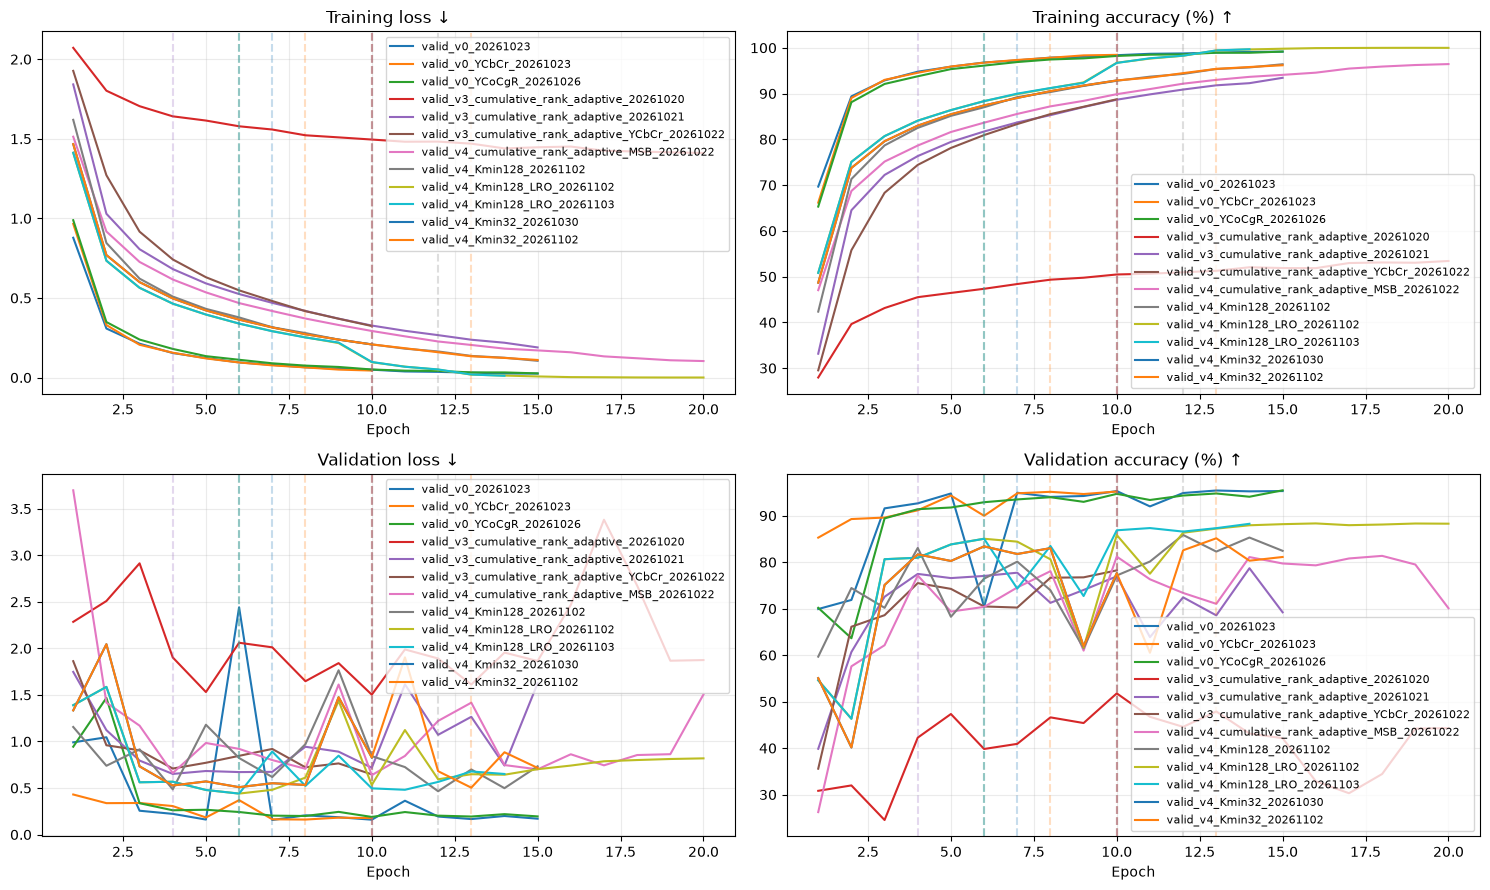

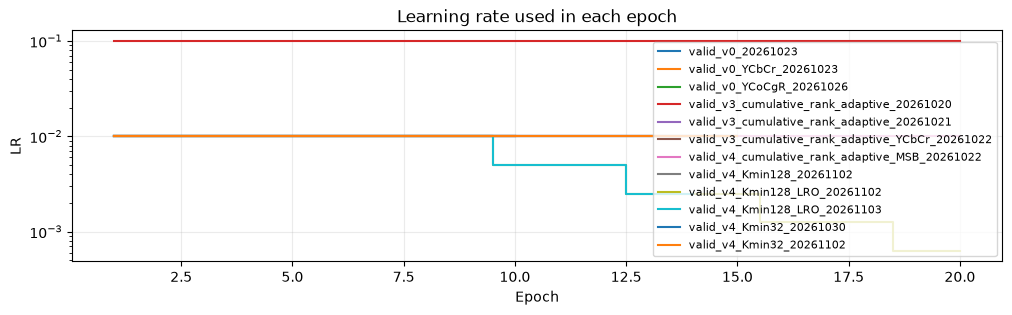

Epoch history: valid_v0_20261023


,epoch,loss,accuracy,val_loss,val_accuracy,validation_seconds,lr,training_seconds,training_device
0,1,0.878551,69.671111,0.990668,69.92,40.981690,0.01,636.940804,cuda
1,2,0.308286,89.391111,1.045138,71.88,27.032819,0.01,473.676209,cuda
2,3,0.213020,92.877778,0.256116,91.58,19.857823,0.01,464.974238,cuda
3,4,0.154337,94.780000,0.222495,92.66,25.840952,0.01,431.604753,cuda
4,5,0.123199,95.875556,0.161233,94.78,26.834055,0.01,496.758627,cuda
5,6,0.095295,96.791111,2.441282,70.42,19.488455,0.01,413.652205,cuda
6,7,0.079958,97.251111,0.156421,94.94,19.510401,0.01,414.796476,cuda
7,8,0.064491,97.860000,0.206728,94.04,19.770749,0.01,417.289671,cuda
8,9,0.056113,98.044444,0.186334,94.24,19.558500,0.01,415.893935,cuda
9,10,0.049793,98.380000,0.159877,95.30,19.483735,0.01,415.050669,cuda


In [18]:
PLOT_RUNS = list(results)  # Replace with a smaller list of run labels if needed.
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for label in PLOT_RUNS:
    history = results[label]["history"]
    if "epoch" not in history:
        continue
    for ax, key in zip(axes.flat, ["loss", "accuracy", "val_loss", "val_accuracy"]):
        if key in history:
            line, = ax.plot(history["epoch"], history[key], label=label)
            best_epoch = results[label]["summary"]["best_epoch"]
            if best_epoch is not None:
                ax.axvline(best_epoch, color=line.get_color(), alpha=0.25, linestyle="--")
for ax, title in zip(axes.flat, ["Training loss ↓", "Training accuracy (%) ↑", "Validation loss ↓", "Validation accuracy (%) ↑"]):
    ax.set(title=title, xlabel="Epoch")
    ax.grid(alpha=0.25)
    if ax.lines:
        ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(12, 3))
for label in PLOT_RUNS:
    history = results[label]["history"]
    if {"epoch", "lr"}.issubset(history.columns):
        ax.step(history["epoch"], history["lr"], where="mid", label=label)
ax.set(title="Learning rate used in each epoch", xlabel="Epoch", ylabel="LR", yscale="log")
if ax.lines:
    ax.legend(fontsize=8)
ax.grid(alpha=0.25)
plt.show()

DETAIL_RUN = PLOT_RUNS[0]
print(f"Epoch history: {DETAIL_RUN}")
display(results[DETAIL_RUN]["history"])

## 6. Test metrics by class
Derived from the saved confusion counts, with rows = true class and columns = prediction. Undefined ratios are shown as missing. No test evaluation is triggered. These tables describe the saved test epoch, which can differ from both the best-validation and last epochs.

In [19]:
def class_metrics(label, result):
    counts = result["test"].get("confusion_counts")
    if counts is None:
        return None, None
    counts = np.asarray(counts, dtype=float)
    if counts.ndim != 2 or counts.shape[0] != counts.shape[1] or not np.isfinite(counts).all() or (counts < 0).any():
        warnings.warn(f"Invalid confusion counts for {label}; skipped.")
        return None, None
    true_positive = np.diag(counts)
    support, predicted = counts.sum(axis=1), counts.sum(axis=0)
    divide = lambda a, b: np.divide(a, b, out=np.full_like(a, np.nan), where=b != 0)
    mapping = result["idx_to_class"]
    names = [mapping.get(i, mapping.get(str(i), str(i))) for i in range(len(counts))]
    frame = pd.DataFrame({"class": names, "precision": 100 * divide(true_positive, predicted),
                          "recall": 100 * divide(true_positive, support),
                          "f1": 100 * divide(2 * true_positive, support + predicted),
                          "support": support.astype(int), "run": label})
    return frame, counts

per_class_frames, matrices = [], {}
for label, result in results.items():
    frame, counts = class_metrics(label, result)
    if frame is not None:
        per_class_frames.append(frame)
        matrices[label] = counts
per_class = pd.concat(per_class_frames, ignore_index=True) if per_class_frames else pd.DataFrame()
CLASS_METRIC = "recall"  # "precision", "recall" or "f1"
if per_class.empty:
    print("No saved test confusion matrices available.")
else:
    class_table = per_class.pivot(index="class", columns="run", values=CLASS_METRIC)
    display(class_table.style.format("{:.2f}%", na_rep="—")
            .background_gradient(cmap="Blues", vmin=0, vmax=100, axis=None))
    print("Full per-class table (support is the true-class sample count):")
    display(per_class)

run,valid_v0_20261023,valid_v0_YCbCr_20261023,valid_v0_YCoCgR_20261026,valid_v3_cumulative_rank_adaptive_20261020,valid_v3_cumulative_rank_adaptive_20261021,valid_v3_cumulative_rank_adaptive_YCbCr_20261022,valid_v4_Kmin128_20261102,valid_v4_Kmin128_LRO_20261102,valid_v4_Kmin128_LRO_20261103,valid_v4_Kmin32_20261030,valid_v4_Kmin32_20261102,valid_v4_cumulative_rank_adaptive_MSB_20261022
class,,,,,,,,,,,,
airplane,94.30%,96.40%,96.20%,57.00%,79.80%,77.20%,85.80%,90.60%,89.70%,89.00%,87.90%,89.20%
automobile,98.60%,96.60%,98.10%,51.40%,79.60%,89.80%,95.50%,94.90%,93.20%,85.50%,90.60%,89.20%
bird,91.60%,91.80%,93.70%,8.00%,66.20%,53.80%,79.00%,84.00%,84.10%,83.80%,76.00%,75.00%
cat,92.60%,87.50%,78.70%,47.40%,71.40%,80.20%,77.20%,76.60%,74.30%,72.30%,66.20%,68.70%
deer,95.50%,97.40%,96.60%,54.30%,72.80%,78.00%,84.60%,78.70%,88.40%,76.50%,80.90%,82.60%
dog,89.60%,94.80%,93.60%,68.60%,61.10%,50.30%,79.20%,71.90%,84.90%,68.90%,79.30%,67.90%
frog,96.30%,95.90%,98.10%,58.60%,84.90%,82.20%,91.20%,91.00%,90.40%,93.20%,92.80%,77.90%
horse,95.70%,95.30%,96.10%,38.80%,77.50%,80.00%,88.10%,91.40%,90.50%,79.10%,93.70%,84.30%
ship,97.80%,95.60%,95.80%,57.70%,89.70%,93.10%,90.60%,90.00%,93.30%,89.60%,93.40%,87.30%


Full per-class table (support is the true-class sample count):


,class,precision,recall,f1,support,run
0,airplane,97.518097,94.3,95.882054,1000,valid_v0_20261023
1,automobile,93.548387,98.6,96.007790,1000,valid_v0_20261023
2,bird,95.416667,91.6,93.469388,1000,valid_v0_20261023
3,cat,82.604817,92.6,87.317303,1000,valid_v0_20261023
4,deer,95.691383,95.5,95.595596,1000,valid_v0_20261023
...,...,...,...,...,...,...
115,dog,76.841085,79.3,78.051181,1000,valid_v4_Kmin32_20261102
116,frog,79.725086,92.8,85.767098,1000,valid_v4_Kmin32_20261102
117,horse,81.620209,93.7,87.243948,1000,valid_v4_Kmin32_20261102
118,ship,87.208217,93.4,90.197972,1000,valid_v4_Kmin32_20261102


## 7. Confusion matrices
All panels use the same 0–100% scale. Missing-support rows are masked. Check class mappings and test example identities before interpreting differences.

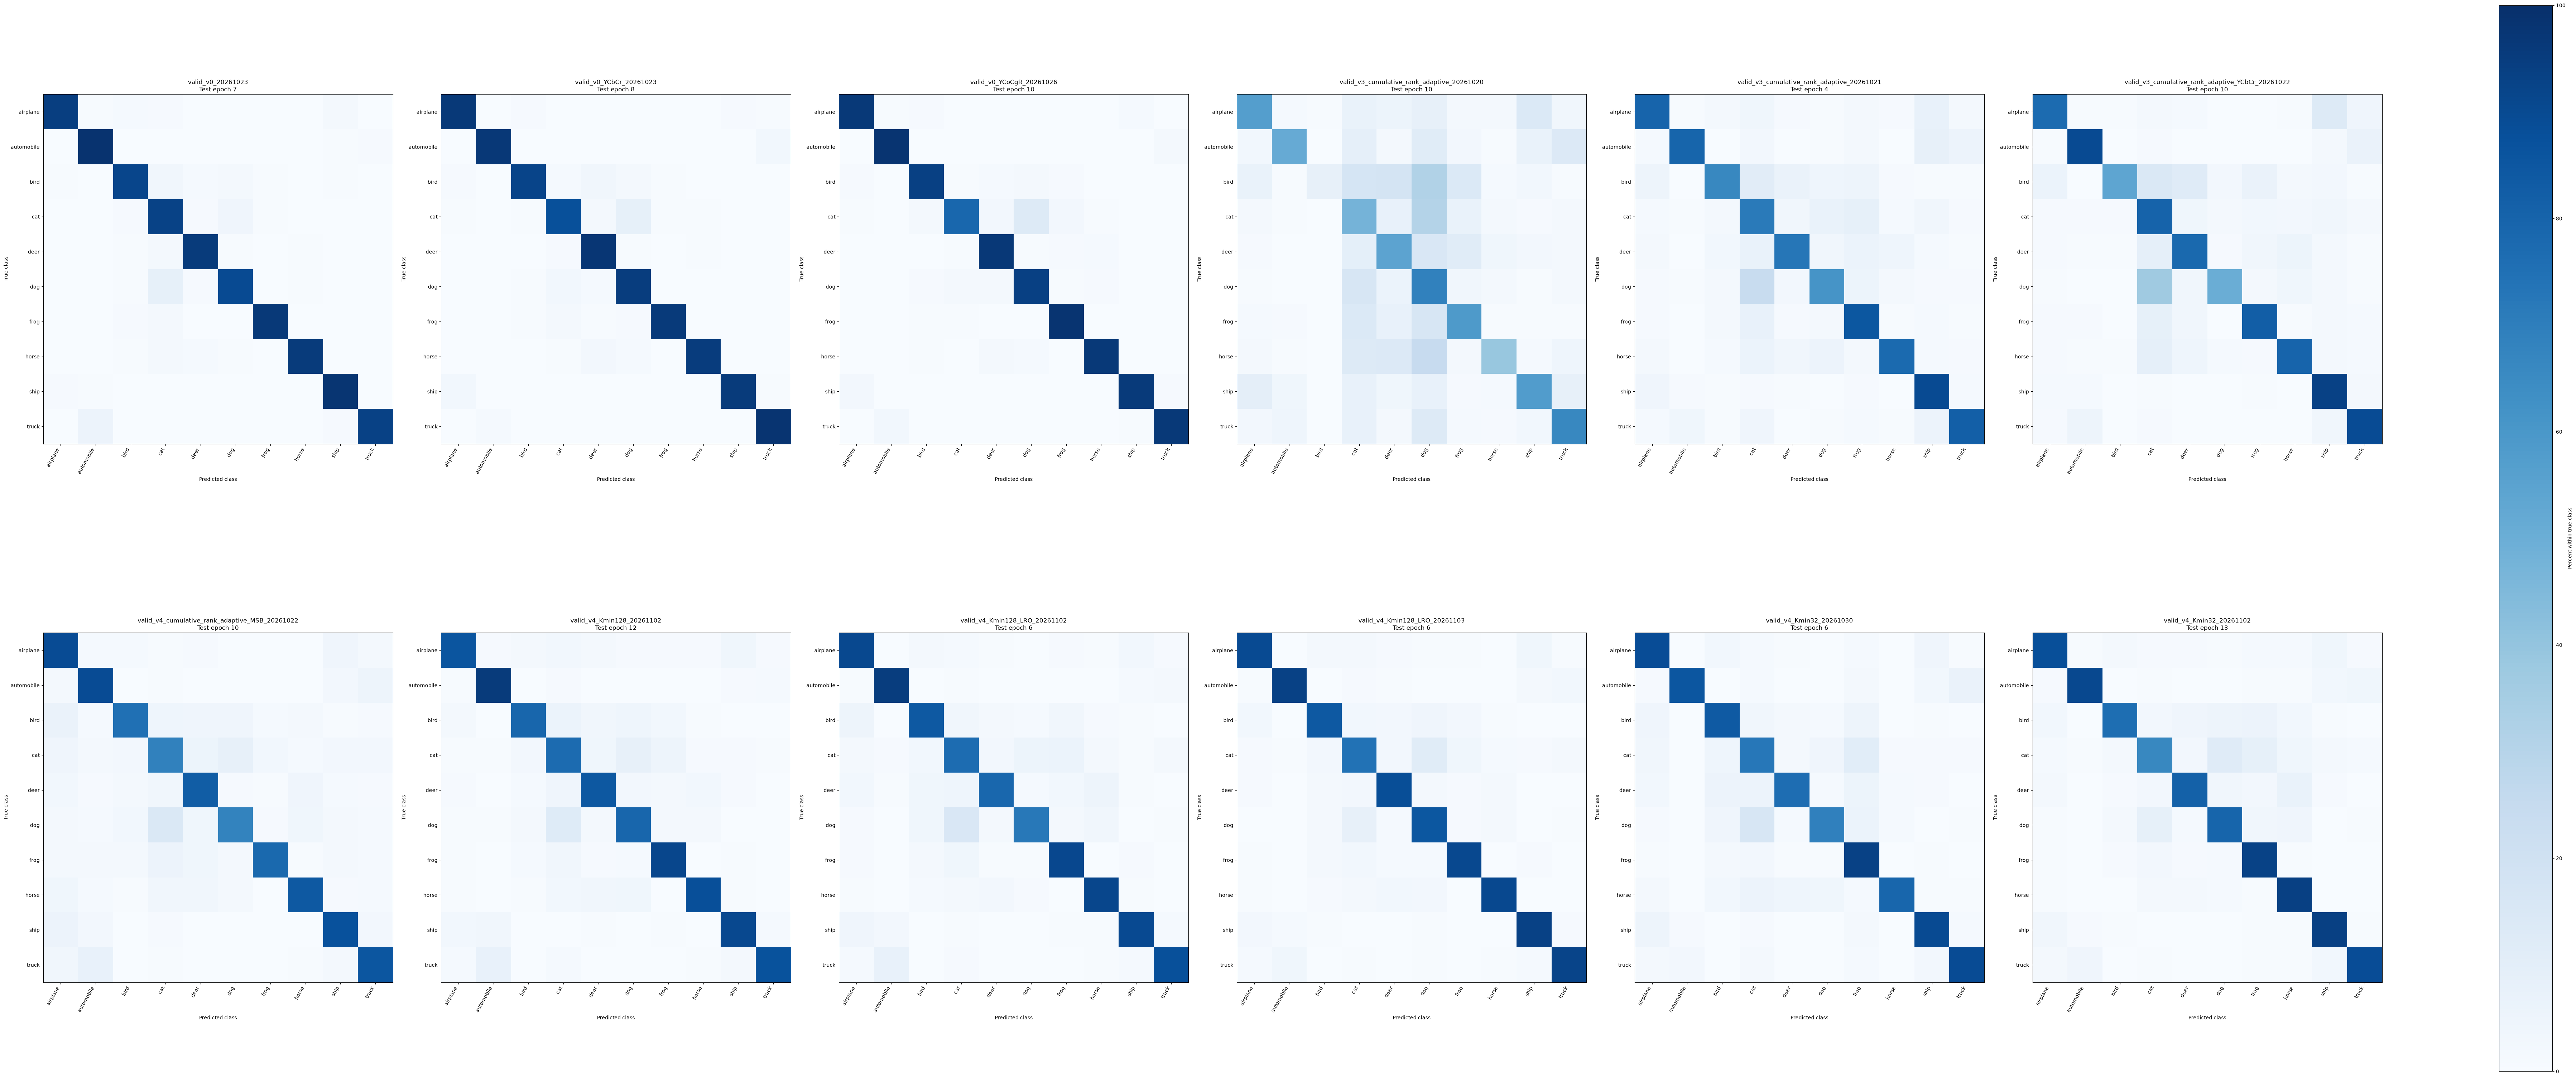

In [25]:
MATRIX_RUNS = [label for label in PLOT_RUNS if label in matrices]
if MATRIX_RUNS:
    fig, axes = plt.subplots(2, len(MATRIX_RUNS)//2, figsize=(6 * len(MATRIX_RUNS), 30), squeeze=False,
                             layout="constrained")
    for ax, label in zip(axes.flat, MATRIX_RUNS):
        counts = matrices[label]
        support = counts.sum(axis=1, keepdims=True)
        normalized = np.divide(100 * counts, support, out=np.full_like(counts, np.nan), where=support != 0)
        names = per_class.loc[per_class["run"].eq(label), "class"].tolist()
        im = ax.imshow(np.ma.masked_invalid(normalized), cmap="Blues", vmin=0, vmax=100)
        ax.set(title=f"{label}\nTest epoch {results[label]['test'].get('epoch', '?')}",
               xlabel="Predicted class", ylabel="True class",
               xticks=range(len(names)), yticks=range(len(names)), xticklabels=names, yticklabels=names)
        plt.setp(ax.get_xticklabels(), rotation=60, ha="right")
    fig.colorbar(im, ax=axes.ravel().tolist(), label="Percent within true class")
    plt.show()
else:
    print("No confusion matrices for the selected runs.")

## 8. Optional export
Set `EXPORT = True` to write CSV tables under `output/experiment_comparisons`. The default is read-only. Existing exports in that folder are replaced when this cell is enabled.

In [ ]:
EXPORT = False
EXPORT_DIR = PROJECT_ROOT / "output" / "experiment_comparisons"
if EXPORT:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(EXPORT_DIR / "summary.csv")
    deltas.to_csv(EXPORT_DIR / "differences.csv")
    for label, result in results.items():
        safe_name = hashlib.sha256(label.encode()).hexdigest()[:12]
        result["history"].to_csv(EXPORT_DIR / f"history_{safe_name}.csv", index=False)
    if not per_class.empty:
        per_class.to_csv(EXPORT_DIR / "per_class.csv", index=False)
    print(f"Tables exported to {EXPORT_DIR}")